# AI-Driven Churn Prediction for Personalized Retention in E-Commerce

The Chief Marketing Officer (CMO) of a leading retail e-commerce platform has identified a growing rate of customer attrition, negatively affecting average order value and customer lifetime value (CLV). To address this challenge, the Data & AI team has been tasked with developing a machine learning model to identify customers at high risk of churning.

The project aims to transform customer data into actionable insights that support proactive, personalized retention strategies, including targeted offers and customer communications. By identifying at-risk customers and understanding the factors associated with churn, the business can make more informed marketing decisions, improve customer loyalty, and optimize retention efforts.

Ultimately, this project demonstrates how predictive analytics and explainable machine learning can support data-driven decision-making and improve marketing effectiveness.

**Workflow:** data inspection → EDA → cleaning → leakage-safe preprocessing → model comparison and tuning → evaluation → explainability → customer risk scoring → saved model.

> Place `data (1).xlsx` (or update `DATA_PATH`) in the same directory as this notebook. The notebook has not been run against your local dataset, so metrics will be produced when you execute it.


## 1. Import libraries and configure the experiment

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance
import joblib

# Optional model/explainability libraries. The notebook can still run without them.
try:
    from xgboost import XGBClassifier
    import xgboost as xgb
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    print("XGBoost is not installed; XGBoost model cells will be skipped.")

try:
    from catboost import CatBoostClassifier
    HAS_CATBOOST = True
except ImportError:
    HAS_CATBOOST = False
    print("CatBoost is not installed; CatBoost model cells will be skipped.")

try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False
    print("SHAP is not installed; SHAP explainability will be skipped.")

RANDOM_STATE = 42
DATA_PATH = Path("Telco-Customer-Churn.xlsx")
TARGET = "Churn"
ID_COL = "CustomerID"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)


CatBoost is not installed; CatBoost model cells will be skipped.


## 2. Load the dataset and inspect its structure

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Put data (1).xlsx next to this notebook "
        "or update DATA_PATH to the correct file."
    )

if DATA_PATH.suffix.lower() in {".xlsx", ".xls"}:
    df = pd.read_excel(DATA_PATH)
else:
    df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head(10))
df.info()


Dataset shape: 5,630 rows × 20 columns


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001.0,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002.0,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003.0,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004.0,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005.0,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60
5,50006.0,1,0.0,Computer,1,22.0,Debit Card,Female,3.0,5,Mobile Phone,5,Single,2,1,22.0,4.0,6.0,7.0,139.19
6,50007.0,1,NaN,Phone,3,11.0,Cash on Delivery,Male,2.0,3,Laptop & Accessory,2,Divorced,4,0,14.0,0.0,1.0,0.0,120.86
7,50008.0,1,NaN,Phone,1,6.0,CC,Male,3.0,3,Mobile,2,Divorced,3,1,16.0,2.0,2.0,0.0,122.93
8,50009.0,1,13.0,Phone,3,9.0,E wallet,Male,NaN,4,Mobile,3,Divorced,2,1,14.0,0.0,1.0,2.0,126.83
9,50010.0,1,NaN,Phone,1,31.0,Debit Card,Male,2.0,5,Mobile,3,Single,2,0,12.0,1.0,1.0,1.0,122.93


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5628 non-null   float64
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5628 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

In [3]:
# Inspect data types, missingness, and distinct values.
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=False)
}).sort_values("missing_values", ascending=False))

print("Duplicate rows:", df.duplicated().sum())
if ID_COL in df.columns:
    print("Duplicate customer IDs:", df[ID_COL].duplicated().sum())


,dtype,missing_values,missing_percent,unique_values
DaySinceLastOrder,float64,307,5.45,23
OrderAmountHikeFromlastYear,float64,265,4.71,17
Tenure,float64,264,4.69,37
OrderCount,float64,258,4.58,17
CouponUsed,float64,256,4.55,18
HourSpendOnApp,float64,255,4.53,7
WarehouseToHome,float64,251,4.46,35
CustomerID,float64,2,0.04,5629
Gender,object,2,0.04,3
Churn,int64,0,0.00,2


Duplicate rows: 0
Duplicate customer IDs: 1


## 3. Data quality checks and target preparation

In [4]:
if TARGET not in df.columns:
    raise ValueError(f"Target column {TARGET!r} was not found. Available columns: {df.columns.tolist()}")

# Work on a copy; preserve the original values for traceability.
df_raw = df.copy()

# Normalize common numeric columns without dropping rows or changing row alignment.
# Invalid values become NaN and are handled by the preprocessing pipeline later.
likely_numeric = [
    "Tenure", "CityTier", "WarehouseToHome", "HourSpendOnApp",
    "NumberOfDeviceRegistered", "SatisfactionScore", "NumberOfAddress",
    "Complain", "OrderAmountHikeFromlastYear", "CouponUsed", "OrderCount",
    "DaySinceLastOrder", "CashbackAmount"
]
for col in likely_numeric:
    if col in df_raw.columns:
        df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

# Encode the target safely. The common e-commerce dataset uses 0/1, but Yes/No is also supported.
raw_target = df_raw[TARGET]
if pd.api.types.is_numeric_dtype(raw_target):
    numeric_target = pd.to_numeric(raw_target, errors="coerce")
    valid = numeric_target.isin([0, 1])
    df_raw = df_raw.loc[valid].copy()
    df_raw[TARGET] = numeric_target.loc[valid].astype(int)
else:
    normalized_target = raw_target.astype("string").str.strip().str.lower()
    target_map = {"no": 0, "yes": 1, "0": 0, "1": 1, "false": 0, "true": 1}
    mapped_target = normalized_target.map(target_map)
    valid = mapped_target.notna()
    df_raw = df_raw.loc[valid].copy()
    df_raw[TARGET] = mapped_target.loc[valid].astype(int)

if df_raw.empty:
    raise ValueError("No valid target values remain. Inspect the original Churn column before continuing.")
if df_raw[TARGET].nunique() != 2:
    raise ValueError(f"Expected a binary target with values 0 and 1; found {df_raw[TARGET].unique()}.")

print("Target counts (0 = retained, 1 = churn):")
display(df_raw[TARGET].value_counts().sort_index().rename(index={0: "No churn", 1: "Churn"}).to_frame("customers"))
print(f"Churn rate: {df_raw[TARGET].mean():.1%}")


Target counts (0 = retained, 1 = churn):


,customers
Churn,
No churn,4682
Churn,948


Churn rate: 16.8%


## 4. Exploratory data analysis (EDA)

### 4.1 Target distribution

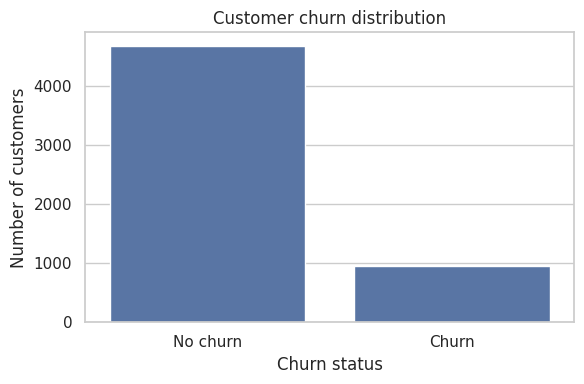

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_raw, x=TARGET, ax=ax)
ax.set_xticks([0, 1], labels=["No churn", "Churn"])
ax.set_title("Customer churn distribution")
ax.set_xlabel("Churn status")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()


### 4.2 Categorical feature distributions by churn

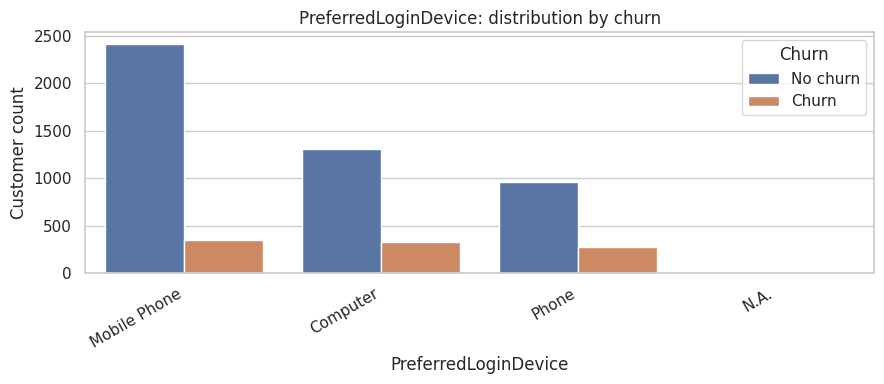

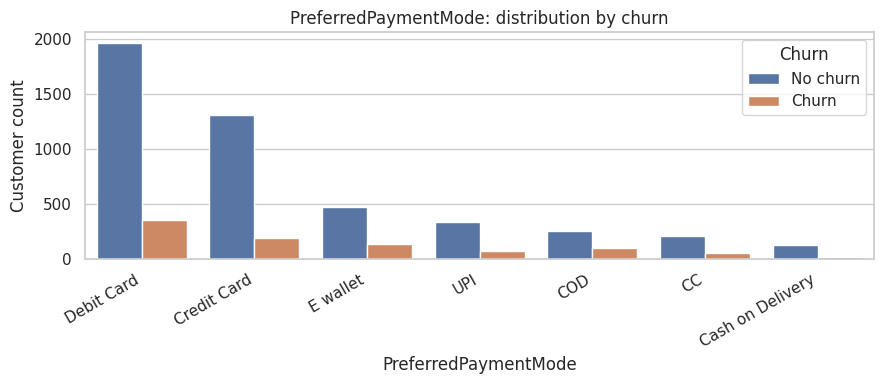

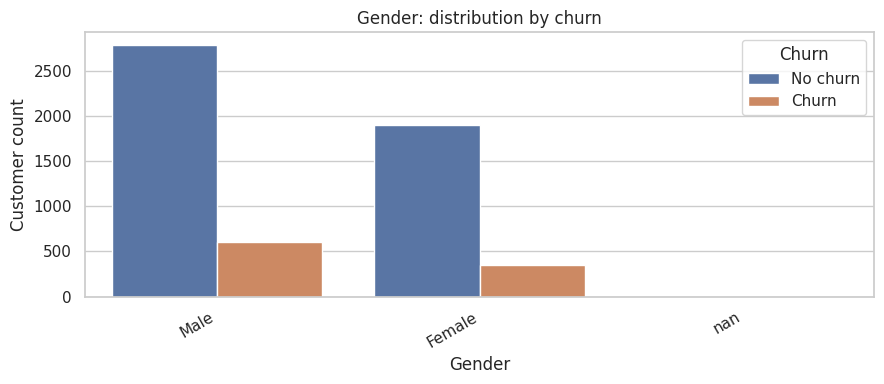

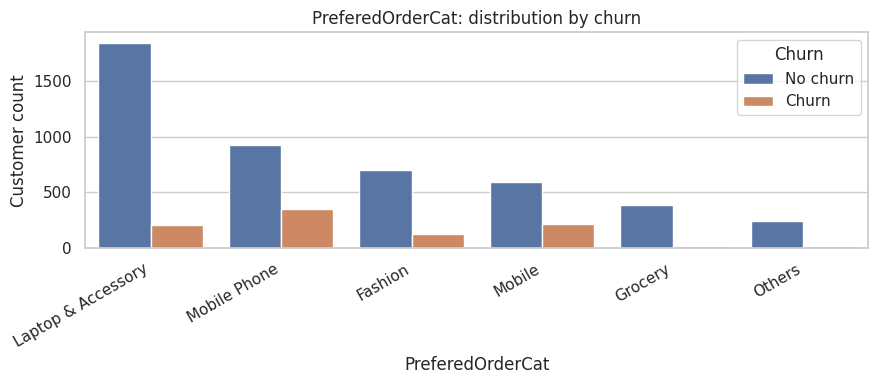

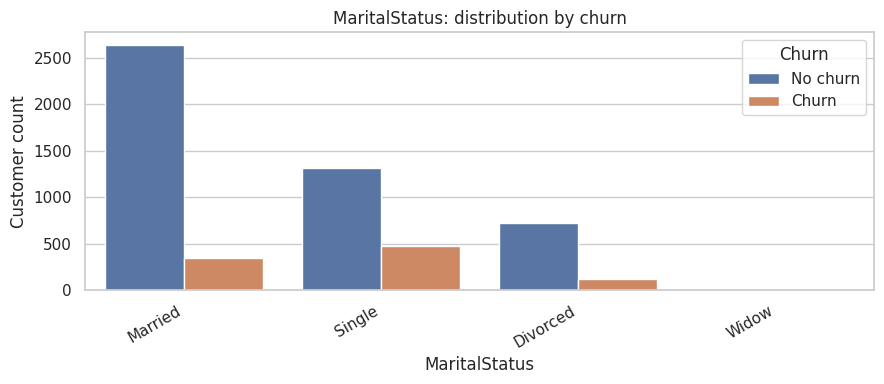

In [6]:
# CustomerID is an identifier, not a predictor. Exclude it from EDA plots.
cat_for_eda = [c for c in df_raw.select_dtypes(include=["object", "string", "category"]).columns
               if c not in {ID_COL, TARGET}]

for col in cat_for_eda:
    if df_raw[col].nunique(dropna=False) <= 15:
        plt.figure(figsize=(9, 4))
        sns.countplot(data=df_raw, x=col, hue=TARGET, order=df_raw[col].value_counts(dropna=False).index)
        plt.title(f"{col}: distribution by churn")
        plt.xlabel(col)
        plt.ylabel("Customer count")
        plt.xticks(rotation=30, ha="right")
        plt.legend(title="Churn", labels=["No churn", "Churn"])
        plt.tight_layout()
        plt.show()


### 4.3 Numerical feature distributions and summary statistics

,count,mean,std,min,1%,10%,25%,50%,75%,90%,95%,99%,max
Tenure,5366.0,10.189899,8.557241,0.0,0.00,1.00,2.00,9.00,16.0000,23.00,27.0000,30.0000,61.0
CityTier,5630.0,1.654707,0.915389,1.0,1.00,1.00,1.00,1.00,3.0000,3.00,3.0000,3.0000,3.0
WarehouseToHome,5379.0,15.639896,8.531475,5.0,6.00,7.00,9.00,14.00,20.0000,30.00,33.0000,35.0000,127.0
HourSpendOnApp,5375.0,2.931535,0.721926,0.0,2.00,2.00,2.00,3.00,3.0000,4.00,4.0000,4.0000,5.0
NumberOfDeviceRegistered,5630.0,3.688988,1.023999,1.0,1.00,3.00,3.00,4.00,4.0000,5.00,5.0000,6.0000,6.0
SatisfactionScore,5630.0,3.066785,1.380194,1.0,1.00,1.00,2.00,3.00,4.0000,5.00,5.0000,5.0000,5.0
NumberOfAddress,5630.0,4.214032,2.583586,1.0,1.00,2.00,2.00,3.00,6.0000,8.00,10.0000,11.0000,22.0
Complain,5630.0,0.284902,0.451408,0.0,0.00,0.00,0.00,0.00,1.0000,1.00,1.0000,1.0000,1.0
OrderAmountHikeFromlastYear,5365.0,15.707922,3.675485,11.0,11.00,12.00,13.00,15.00,18.0000,21.00,23.0000,25.0000,26.0
CouponUsed,5374.0,1.751023,1.894621,0.0,0.00,0.00,1.00,1.00,2.0000,4.00,6.0000,9.0000,16.0


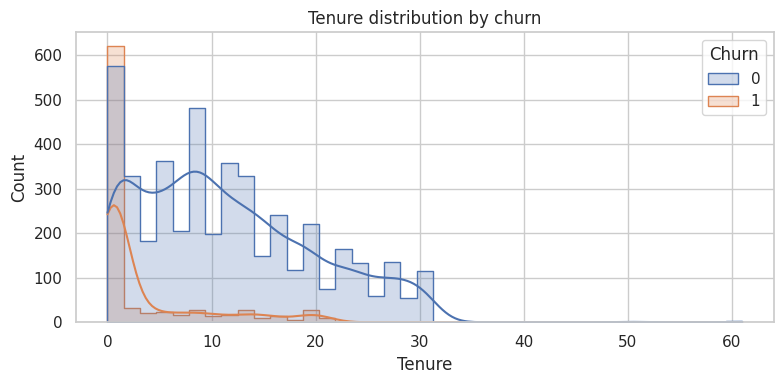

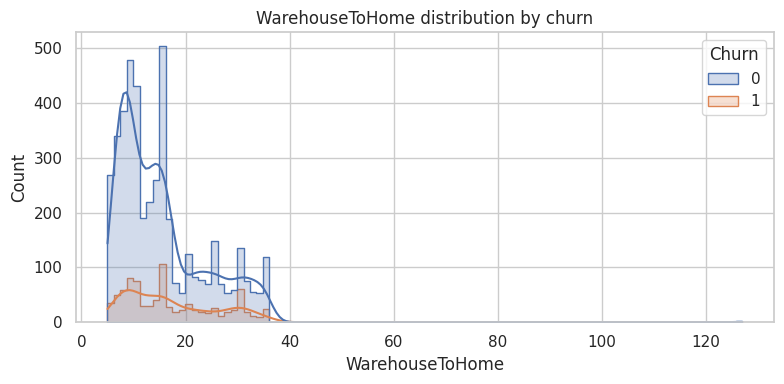

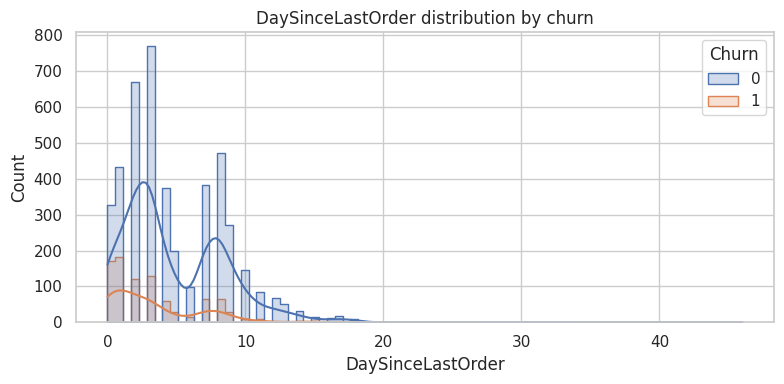

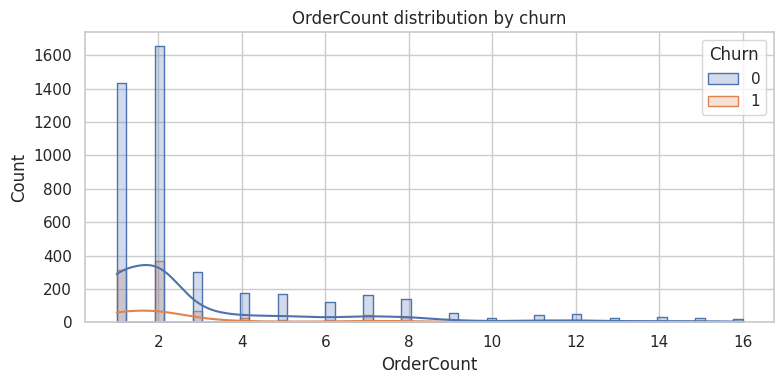

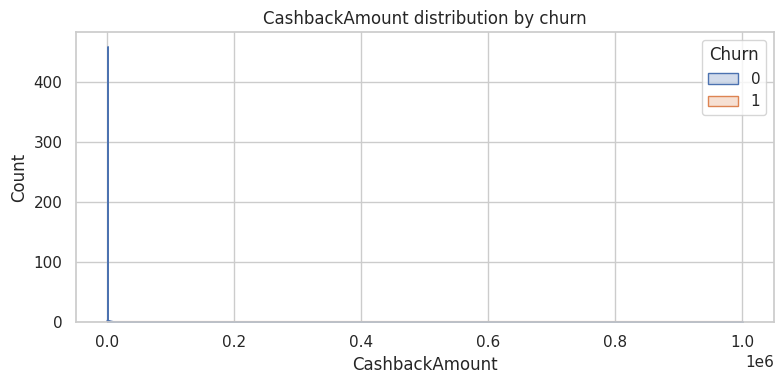

In [7]:
num_for_eda = [c for c in df_raw.select_dtypes(include=np.number).columns if c != TARGET]
num_for_eda = [c for c in num_for_eda if c != ID_COL]

if num_for_eda:
    display(df_raw[num_for_eda].describe(percentiles=[.01, .10, .25, .50, .75, .90, .95, .99]).T)

for col in ["Tenure", "WarehouseToHome", "DaySinceLastOrder", "OrderCount", "CashbackAmount"]:
    if col in df_raw.columns:
        plt.figure(figsize=(8, 4))
        sns.histplot(data=df_raw, x=col, hue=TARGET, kde=(df_raw[col].nunique() > 10), element="step", stat="count", common_norm=False)
        plt.title(f"{col} distribution by churn")
        plt.tight_layout()
        plt.show()


### 4.4 Correlation between numerical features

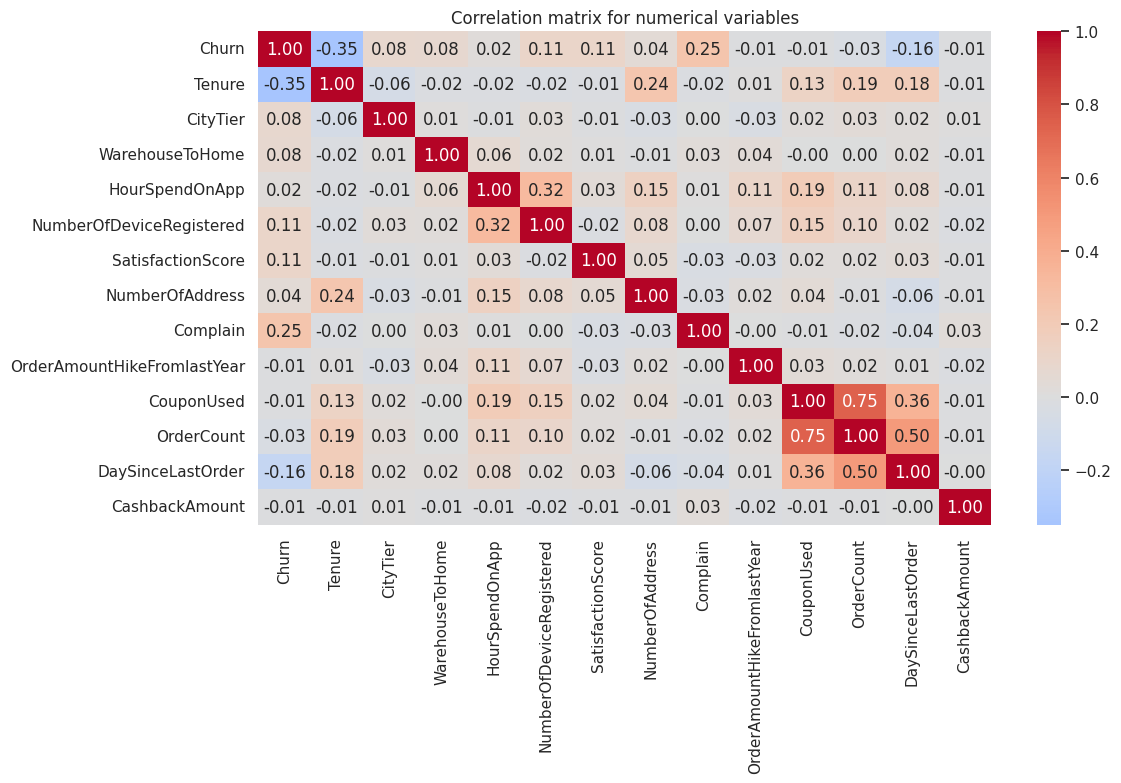

In [8]:
numeric_corr_cols = [c for c in df_raw.select_dtypes(include=np.number).columns if c != ID_COL]
if len(numeric_corr_cols) >= 2:
    plt.figure(figsize=(12, 8))
    sns.heatmap(df_raw[numeric_corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation matrix for numerical variables")
    plt.tight_layout()
    plt.show()


### EDA notes
After running the cells, record the observed churn rate, any missing values, possible outliers, and features whose distributions differ across churn groups. These patterns are descriptive and should not be interpreted as causal effects.

## 5. Data cleaning and feature preparation

In [9]:
df_clean = df_raw.copy()

# Remove fully duplicated rows. If each customer should appear only once, keep the first
# record per CustomerID after checking duplicate IDs above.
rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
print(f"Removed {rows_before - len(df_clean)} fully duplicated rows.")

if ID_COL in df_clean.columns:
    duplicate_ids = int(df_clean[ID_COL].duplicated().sum())
    print(f"Duplicate customer IDs after full-row deduplication: {duplicate_ids}")
    # Do not automatically drop repeated IDs unless the dataset's row-level meaning confirms
    # that each ID should have exactly one record.

# Remove records with an unknown target (target cleaning above should already have done this).
df_clean = df_clean.dropna(subset=[TARGET]).copy()

print("Missing values before model preprocessing:")
display(df_clean.isna().sum().sort_values(ascending=False).to_frame("missing_values").head(20))
print("Cleaned dataset shape:", df_clean.shape)


Removed 0 fully duplicated rows.
Duplicate customer IDs after full-row deduplication: 1
Missing values before model preprocessing:


,missing_values
DaySinceLastOrder,307
OrderAmountHikeFromlastYear,265
Tenure,264
OrderCount,258
CouponUsed,256
HourSpendOnApp,255
WarehouseToHome,251
CustomerID,2
Gender,2
Churn,0


Cleaned dataset shape: (5630, 20)


**Preprocessing principle:** do not introduce artificial missing values, and do not fit imputers or encoders on the entire dataset before splitting. The model pipeline below learns preprocessing from training folds only. This improves reproducibility and reduces data leakage.

## 6. Define features and create a held-out test set

In [10]:
# Preserve IDs for customer-level reporting, but never use IDs as model features.
customer_ids = df_clean[ID_COL].copy() if ID_COL in df_clean.columns else pd.Series(df_clean.index.astype(str), index=df_clean.index, name="CustomerID")
X = df_clean.drop(columns=[TARGET] + ([ID_COL] if ID_COL in df_clean.columns else []))
y = df_clean[TARGET].astype(int)

# Drop columns with only one observed value: they cannot help discriminate churn.
constant_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
if constant_cols:
    print("Dropping constant columns:", constant_cols)
    X = X.drop(columns=constant_cols)

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, customer_ids.loc[X.index], test_size=0.20,
    stratify=y, random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print(f"Training churn rate: {y_train.mean():.1%}; test churn rate: {y_test.mean():.1%}")


Training set: (4504, 18)
Test set: (1126, 18)
Training churn rate: 16.8%; test churn rate: 16.9%


## 7. Build a reusable preprocessing pipeline

In [11]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
], remainder="drop")

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
Categorical features: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


## 8. Establish baselines and compare candidate models

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
}
if HAS_XGBOOST:
    models["XGBoost"] = XGBClassifier(
        objective="binary:logistic", eval_metric="logloss", tree_method="hist",
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.85, colsample_bytree=0.85, random_state=RANDOM_STATE,
        n_jobs=-1
    )
if HAS_CATBOOST:
    models["CatBoost"] = CatBoostClassifier(
        iterations=300, depth=6, learning_rate=0.05, loss_function="Logloss",
        verbose=False, random_seed=RANDOM_STATE, allow_writing_files=False
    )

scoring = {"roc_auc": "roc_auc", "f1": "f1", "precision": "precision", "recall": "recall", "average_precision": "average_precision"}
cv_rows = []
model_pipelines = {}
for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1, error_score="raise")
    cv_rows.append({"Model": name, **{f"CV {metric}": scores[f"test_{metric}"].mean() for metric in scoring},
                    **{f"SD {metric}": scores[f"test_{metric}"].std() for metric in scoring}})
    model_pipelines[name] = pipe

cv_results = pd.DataFrame(cv_rows).sort_values("CV roc_auc", ascending=False).reset_index(drop=True)
display(cv_results.round(4))


,Model,CV roc_auc,CV f1,CV precision,CV recall,CV average_precision,SD roc_auc,SD f1,SD precision,SD recall,SD average_precision
0,Random Forest,0.9777,0.8162,0.9369,0.7243,0.9286,0.0071,0.0312,0.0117,0.0457,0.0157
1,XGBoost,0.9663,0.8167,0.9069,0.7441,0.8962,0.0080,0.0267,0.0111,0.0433,0.0177
2,Logistic Regression,0.8863,0.5761,0.4493,0.8048,0.6972,0.0123,0.0183,0.0152,0.0481,0.0352


## 9. Tune the strongest tree-based candidate

In [13]:
# Select the best available tree-based candidate by training-only CV ROC-AUC.
tree_candidates = [name for name in ["XGBoost", "CatBoost", "Random Forest"] if name in model_pipelines]
if tree_candidates:
    candidate_name = max(tree_candidates, key=lambda name: float(cv_results.loc[cv_results["Model"] == name, "CV roc_auc"].iloc[0]))
else:
    candidate_name = "Logistic Regression"

print("Candidate selected for tuning:", candidate_name)
base_pipeline = model_pipelines[candidate_name]

if candidate_name == "Random Forest":
    param_distributions = {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 8, 12, 20],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": ["sqrt", 0.7]
    }
elif candidate_name == "XGBoost":
    param_distributions = {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [3, 4, 5, 7],
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.7, 0.85, 1.0]
    }
elif candidate_name == "CatBoost":
    param_distributions = {
        "model__iterations": [200, 300, 500],
        "model__depth": [4, 6, 8],
        "model__learning_rate": [0.02, 0.05, 0.1]
    }
else:
    param_distributions = {}

if param_distributions:
    search = RandomizedSearchCV(
        estimator=base_pipeline, param_distributions=param_distributions,
        n_iter=12, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE,
        n_jobs=1, verbose=1, refit=True
    )
    search.fit(X_train, y_train)
    final_model = search.best_estimator_
    print("Best CV ROC-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)
else:
    final_model = base_pipeline.fit(X_train, y_train)
    print("No tuning grid defined; fitted baseline Logistic Regression.")


Candidate selected for tuning: Random Forest
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV ROC-AUC: 0.9777
Best parameters: {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': None}


## 10. Evaluate the final model on the untouched test set

In [14]:
y_prob = final_model.predict_proba(X_test)[:, 1]
threshold = 0.50
y_pred = (y_prob >= threshold).astype(int)

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "Average precision": average_precision_score(y_test, y_prob)
}, name="Test performance")
display(test_metrics.to_frame().round(4))
print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"], zero_division=0))


,Test performance
Accuracy,0.9725
Precision,0.9938
Recall,0.8421
F1-score,0.9117
ROC-AUC,0.9988
Average precision,0.9940


              precision    recall  f1-score   support

    No churn       0.97      1.00      0.98       936
       Churn       0.99      0.84      0.91       190

    accuracy                           0.97      1126
   macro avg       0.98      0.92      0.95      1126
weighted avg       0.97      0.97      0.97      1126



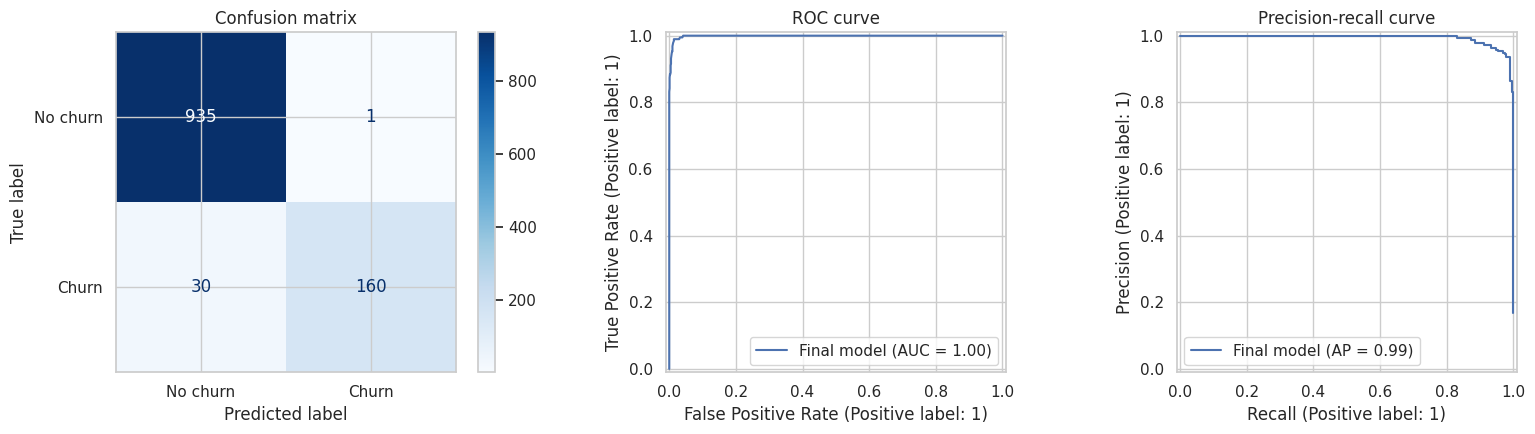

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No churn", "Churn"], cmap="Blues", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name="Final model")
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[2], name="Final model")
axes[0].set_title("Confusion matrix")
axes[1].set_title("ROC curve")
axes[2].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()


**Interpretation:** recall measures the share of actual churners detected; precision measures the share of flagged customers who actually churn. Accuracy can be misleading when churn classes are imbalanced. The test set should be used for final reporting, not repeated model or threshold selection.

## 11. Inspect decision-threshold trade-offs

In [16]:
threshold_rows = []
for t in np.arange(0.20, 0.81, 0.05):
    pred_t = (y_prob >= t).astype(int)
    threshold_rows.append({
        "threshold": round(float(t), 2),
        "precision": precision_score(y_test, pred_t, zero_division=0),
        "recall": recall_score(y_test, pred_t, zero_division=0),
        "f1": f1_score(y_test, pred_t, zero_division=0),
        "customers_flagged": int(pred_t.sum())
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))


,threshold,precision,recall,f1,customers_flagged
0,0.20,0.748,1.000,0.856,254
1,0.25,0.823,1.000,0.903,231
2,0.30,0.879,0.989,0.931,214
3,0.35,0.922,0.989,0.954,204
4,0.40,0.953,0.963,0.958,192
5,0.45,0.977,0.900,0.937,175
6,0.50,0.994,0.842,0.912,161
7,0.55,1.000,0.805,0.892,153
8,0.60,1.000,0.758,0.862,144
9,0.65,1.000,0.653,0.790,124


Use this table to understand the trade-off between contacting more customers and the precision of the list. For unbiased final performance, choose the operating threshold using validation data or business costs, then report final results on a separate untouched test set.

## 12. Explain predictions with permutation importance

,feature,importance_mean,importance_std
0,Tenure,0.110640,0.004087
12,Complain,0.035039,0.002631
10,MaritalStatus,0.011078,0.000484
8,PreferedOrderCat,0.010175,0.001086
11,NumberOfAddress,0.010010,0.000653
17,CashbackAmount,0.006553,0.000834
16,DaySinceLastOrder,0.005268,0.000440
9,SatisfactionScore,0.005114,0.000294
4,PreferredPaymentMode,0.004645,0.000421
1,PreferredLoginDevice,0.003327,0.000445


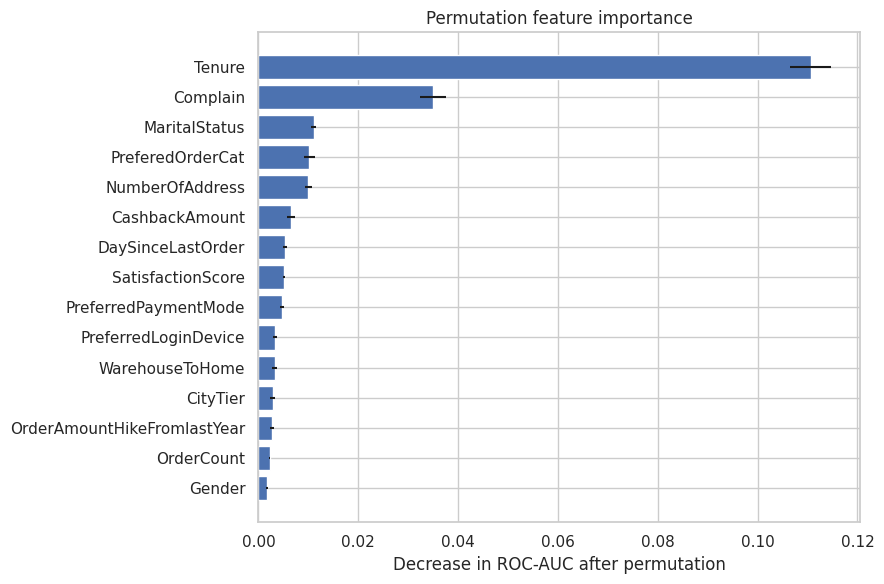

In [17]:
# Permutation importance works on the raw input columns through the full pipeline.
perm = permutation_importance(
    final_model, X_test, y_test, scoring="roc_auc",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=1
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(importance.head(15))

plt.figure(figsize=(9, 6))
top_imp = importance.head(15).sort_values("importance_mean")
plt.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
plt.xlabel("Decrease in ROC-AUC after permutation")
plt.title("Permutation feature importance")
plt.tight_layout()
plt.show()


Permutation importance indicates how much the fitted model relies on each feature for prediction; it does not establish causation. Correlated features can share importance.

## 13. Optional SHAP explainability

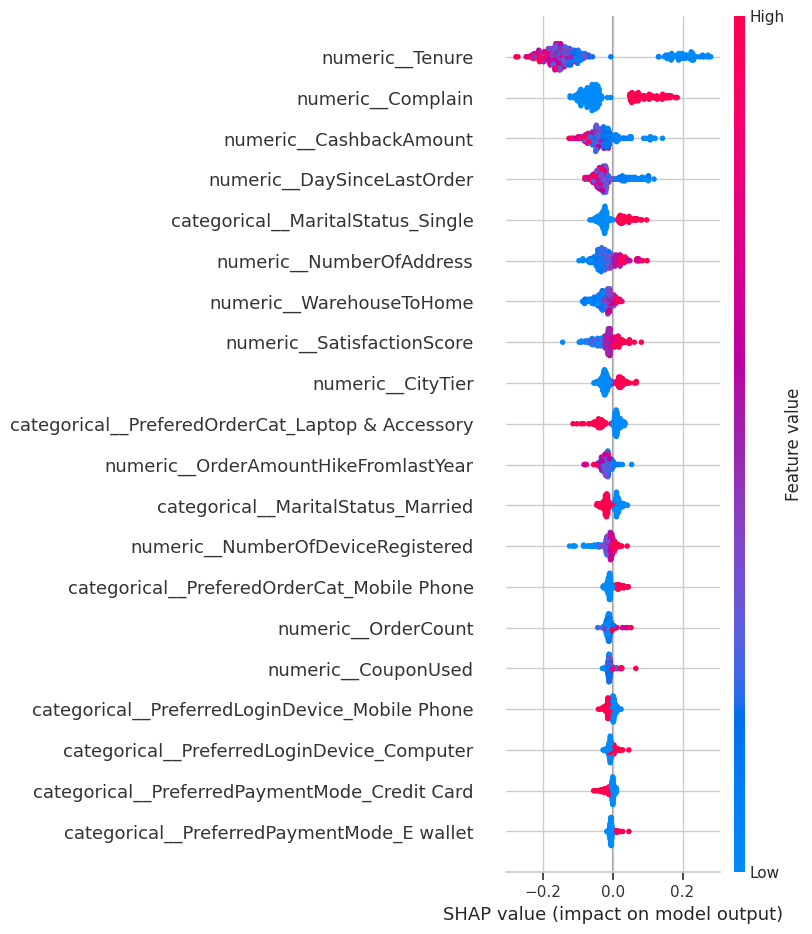

In [18]:
if HAS_SHAP:
    try:
        fitted_preprocessor = final_model.named_steps["preprocessor"]
        fitted_estimator = final_model.named_steps["model"]
        X_test_transformed = fitted_preprocessor.transform(X_test)
        feature_names = fitted_preprocessor.get_feature_names_out()
        # SHAP tree explainers work well with tree estimators. Use a sample to keep this manageable.
        if candidate_name in {"XGBoost", "CatBoost", "Random Forest"}:
            sample_n = min(300, X_test_transformed.shape[0])
            if hasattr(X_test_transformed, "toarray"):
                X_shap = X_test_transformed[:sample_n].toarray()
            else:
                X_shap = np.asarray(X_test_transformed[:sample_n])
            explainer = shap.TreeExplainer(fitted_estimator)
            shap_values = explainer.shap_values(X_shap)
            if isinstance(shap_values, list):
                shap_values = shap_values[-1]
            elif getattr(shap_values, "ndim", 0) == 3:
                shap_values = shap_values[:, :, -1]
            shap.summary_plot(shap_values, X_shap, feature_names=feature_names, show=True)
        else:
            print("SHAP tree explanation skipped for Logistic Regression; permutation importance is available above.")
    except Exception as exc:
        print("SHAP analysis could not be completed in this environment:", exc)
else:
    print("Install shap to enable this optional section: pip install shap")


## 14. Generate a customer-level churn-risk list

In [19]:
# These scores describe the records supplied to this notebook. For real future scoring,
# replace df_clean with a separate, current customer file with the same input columns.
all_features = df_clean.drop(columns=[TARGET] + ([ID_COL] if ID_COL in df_clean.columns else []))
all_ids = df_clean[ID_COL].astype(str) if ID_COL in df_clean.columns else pd.Series(df_clean.index.astype(str), index=df_clean.index)
all_probabilities = final_model.predict_proba(all_features[X.columns])[:, 1]

customer_churn_predictions = pd.DataFrame({
    "CustomerID": all_ids.values,
    "ChurnProbability": all_probabilities
})
customer_churn_predictions["RiskSegment"] = pd.cut(
    customer_churn_predictions["ChurnProbability"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low", "Medium", "High"]
)
customer_churn_predictions = customer_churn_predictions.sort_values("ChurnProbability", ascending=False)
display(customer_churn_predictions.head(10))

high_risk_customers = customer_churn_predictions.query("ChurnProbability >= 0.60").copy()
high_risk_customers.to_csv("high_risk_churn_customers.csv", index=False)
print(f"Saved {len(high_risk_customers):,} high-risk customers to high_risk_churn_customers.csv")


,CustomerID,ChurnProbability,RiskSegment
2817,52818.0,0.995,High
4871,54872.0,0.995,High
4174,54175.0,0.995,High
3401,53402.0,0.995,High
1244,51245.0,0.990,High
3601,53602.0,0.990,High
3378,53379.0,0.990,High
4523,54524.0,0.990,High
4848,54849.0,0.985,High
1561,51562.0,0.985,High


Saved 902 high-risk customers to high_risk_churn_customers.csv


**Retention use:** treat risk scores as decision support, not as automatic proof that a customer will leave. Marketing can test targeted offers or communications, prioritize customers by expected value, and measure incremental retention with controlled experiments.

## 15. Save the complete model pipeline

In [20]:
MODEL_PATH = Path("ecommerce_churn_pipeline.joblib")
joblib.dump({
    "model": final_model,
    "model_name": candidate_name,
    "feature_columns": X.columns.tolist(),
    "target_column": TARGET,
    "positive_class": 1,
    "decision_threshold": threshold,
    "random_state": RANDOM_STATE
}, MODEL_PATH)
print(f"Saved model bundle to: {MODEL_PATH.resolve()}")

# Reload and verify that the saved pipeline can produce probabilities.
loaded_bundle = joblib.load(MODEL_PATH)
loaded_model = loaded_bundle["model"]
print("Reload check probabilities:", loaded_model.predict_proba(X_test.head(3))[:, 1])


Saved model bundle to: /content/ecommerce_churn_pipeline.joblib
Reload check probabilities: [0.02  0.03  0.045]


## 16. Conclusions and next steps

Complete this section after running the notebook:

- **Dataset:** number of customers, churn rate, and key data-quality issues.
- **Best candidate:** model with the strongest cross-validation ROC-AUC.
- **Test performance:** ROC-AUC, precision, recall, F1-score, and average precision.
- **Important predictors:** features identified by permutation importance and, if available, SHAP.
- **Retention action:** how the risk segments could guide outreach and how impact will be measured.
- **Limitations:** possible sampling bias, data leakage risks, changing customer behaviour, and the need for prospective validation.

### Reproducibility checklist
- Confirm the data file and target encoding.
- Run all cells from top to bottom.
- Check model metrics and class balance before making claims.
- Use a separate future customer dataset for operational scoring.
- Monitor performance and retention outcomes after deployment.
